# Stage 12: Fairness analysis and responsible lending
Removing protected attributes from the model ("fairness through unawareness") isn't enough. Other features can act
as **proxies** and reproduce the same disparities. This stage tests the *outcomes* of the lending policy across groups.

**Groups analysed** (from the data, never used as model inputs except age):
`CODE_GENDER`, `AGE_GROUP`, `NAME_FAMILY_STATUS`

**Metrics** (Fairlearn `MetricFrame`; the model's "positive" decision is *decline*)
| Metric | Question it answers |
|---|---|
| Approval rate & **Adverse Impact Ratio** (AIR) | Does any group get approved much less often? AIR < 0.80 (four-fifths rule) is a common red flag |
| False positive rate | Among people who *would have repaid*, who gets wrongly declined more often? |
| False negative rate | Among defaulters, who gets wrongly approved (and ends up over-indebted)? |
| Mean PD vs actual default rate | Is the model equally well calibrated for each group? |
| AUC by group | Does the model rank risk equally well within each group? |

Different fairness definitions **conflict mathematically** when groups have different base rates. You can't equalise
approval rates *and* calibration *and* error rates at the same time. The point is to measure, explain and decide, not to
chase one number.

In [7]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from fairlearn.metrics import MetricFrame, selection_rate
from sklearn.metrics import roc_auc_score

from credit_risk.artifacts import load_feature_contract, load_final_model, load_split_frames, read_json
from credit_risk.config import get_paths, load_config
from credit_risk.fairness import group_report, plot_group_report, summary_metrics
from credit_risk.modeling import CreditRiskModel, train_model
from credit_risk.preprocessing import prepare_X
from credit_risk.thresholds import assign_decision, load_policy
from credit_risk.viz import savefig, set_style

cfg = load_config()
paths = get_paths(cfg)
set_style()
ID, TARGET = cfg["data"]["id_column"], cfg["data"]["target"]
AIR = cfg["fairness"]["air_threshold"]

train, valid, test = load_split_frames(paths)
model = load_final_model(paths)
policy = load_policy(paths["models"] / "decision_policy.json")
y = test[TARGET].to_numpy()
pd_test = model.predict_pd(test)
decline = (pd_test >= policy["decline_at_or_above"]).astype(int)  # 'Refer' counts as approve-eligible here
print(f"Test applicants {len(test):,} | overall approval rate {1 - decline.mean():.1%} | cutoff {policy['decline_at_or_above']:.3f}")

Test applicants 46,127 | overall approval rate 90.6% | cutoff 0.210


## 1. Outcomes by group


=== CODE_GENDER ===


,applicants,actual_default_rate,approval_rate,true_positive_rate,false_positive_rate,false_negative_rate,mean_pd,auc,adverse_impact_ratio
CODE_GENDER,,,,,,,,,
F,"30,390",6.97%,92.1%,34.1%,6.0%,65.9%,7.43%,0.785,0.92
M,"15,735",10.20%,87.6%,42.0%,9.0%,58.0%,9.32%,0.795,0.88


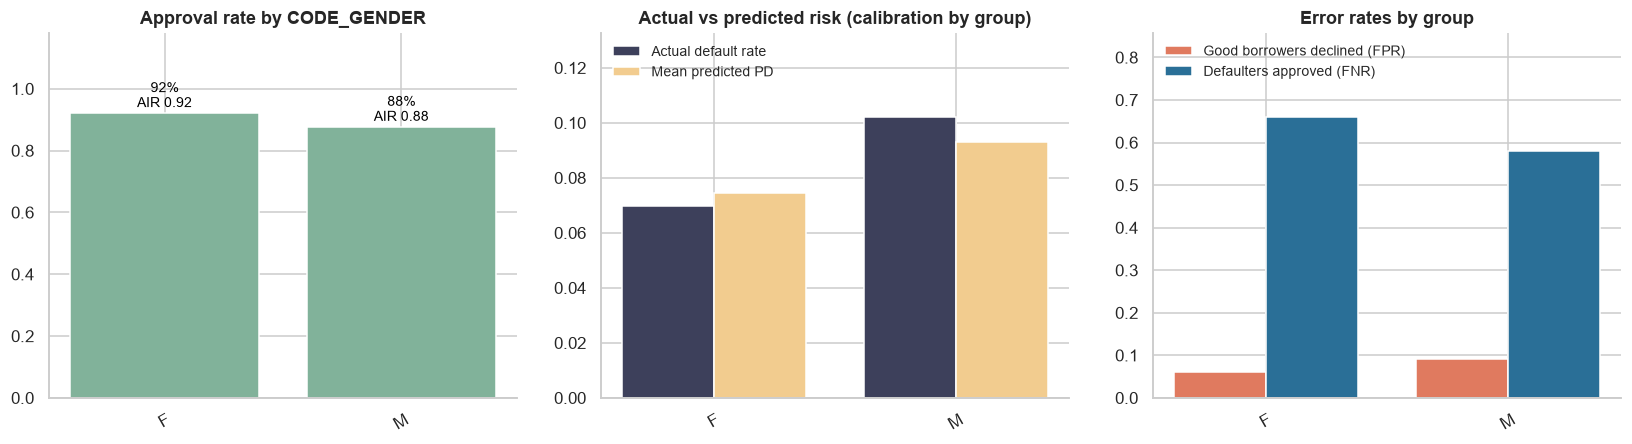


=== AGE_GROUP ===


,applicants,actual_default_rate,approval_rate,true_positive_rate,false_positive_rate,false_negative_rate,mean_pd,auc,adverse_impact_ratio
AGE_GROUP,,,,,,,,,
<25,"1,752",12.84%,78.9%,45.3%,17.5%,54.7%,13.50%,0.735,0.80
25-34,"10,767",10.62%,84.2%,47.8%,12.0%,52.2%,10.74%,0.787,0.85
35-44,"12,609",8.04%,90.4%,38.3%,7.0%,61.7%,8.19%,0.800,0.91
45-54,"10,577",7.29%,92.8%,32.6%,5.2%,67.4%,7.15%,0.800,0.94
55-64,"9,179",5.70%,96.6%,20.5%,2.4%,79.5%,5.46%,0.752,0.97
65+,"1,243",3.86%,99.3%,4.2%,0.6%,95.8%,3.33%,0.750,1.00


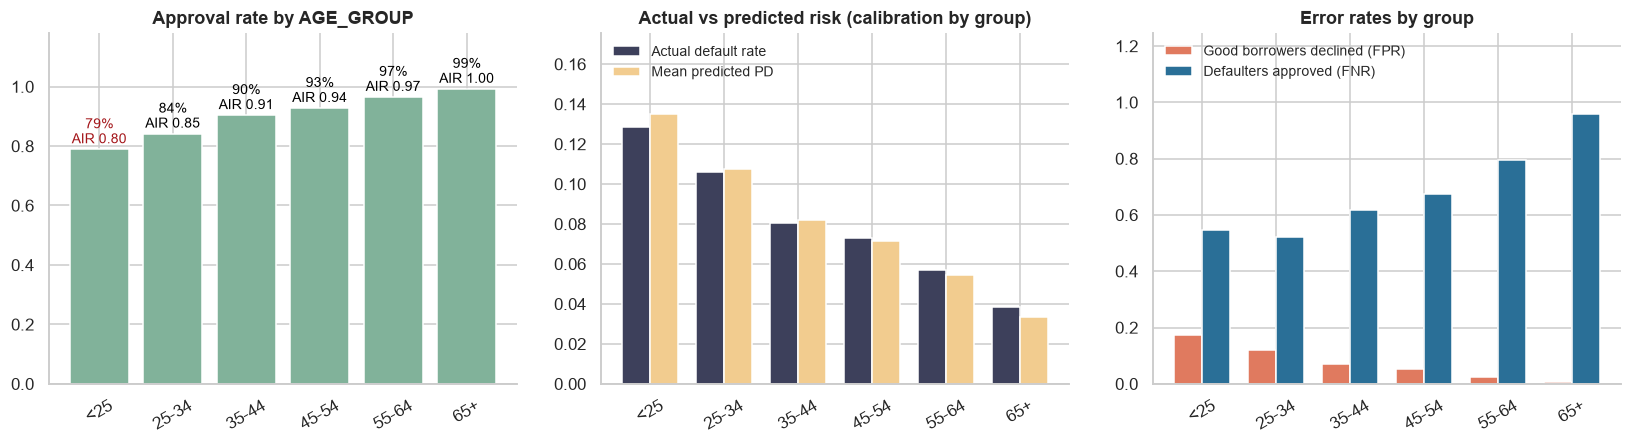


=== NAME_FAMILY_STATUS ===


,applicants,actual_default_rate,approval_rate,true_positive_rate,false_positive_rate,false_negative_rate,mean_pd,auc,adverse_impact_ratio
NAME_FAMILY_STATUS,,,,,,,,,
Civil marriage,"4,460",9.78%,88.5%,41.5%,8.3%,58.5%,8.97%,0.780,0.93
Married,"29,422",7.63%,91.0%,37.4%,6.6%,62.6%,7.82%,0.794,0.96
Separated,"2,938",9.16%,91.9%,32.7%,5.7%,67.3%,7.68%,0.786,0.96
Single / not married,"6,831",9.22%,87.5%,39.7%,9.7%,60.3%,9.46%,0.793,0.92
Widow,"2,476",5.78%,95.3%,25.2%,3.5%,74.8%,6.16%,0.770,1.00


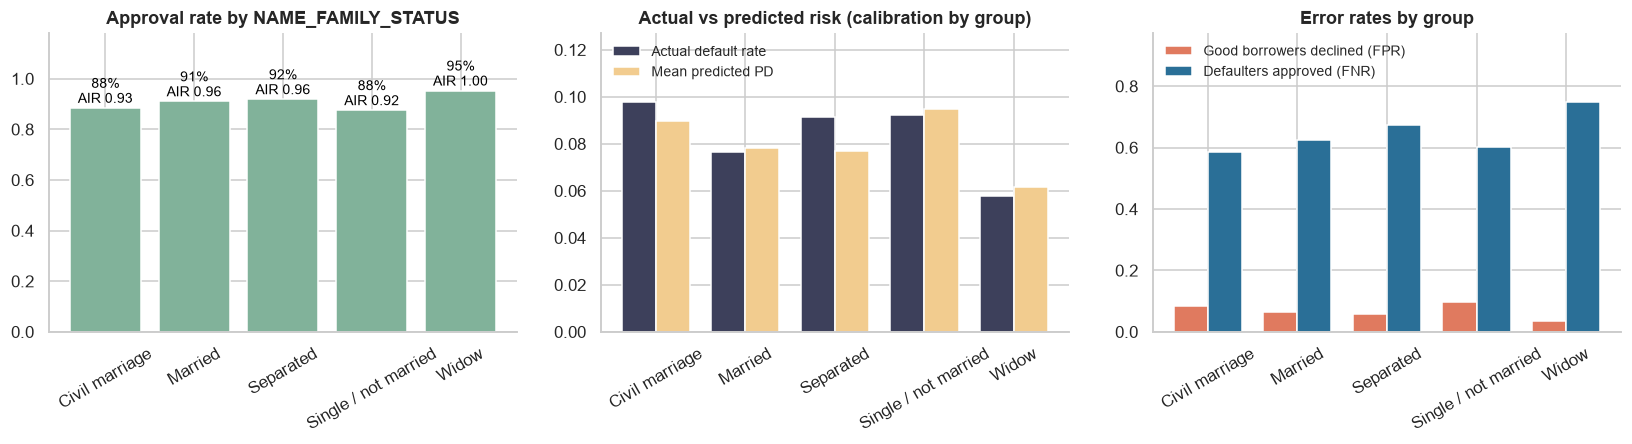

In [8]:
reports, summaries = {}, {}
for attr in cfg["fairness"]["protected_attributes"]:
    s = test[attr].rename(attr)
    rep = group_report(y, decline, pd_test, s)
    rep = rep[rep["applicants"] >= 30]  # tiny groups give unstable rates
    reports[attr] = rep
    summaries[attr] = summary_metrics(y, decline, s, AIR)
    print(f"\n=== {attr} ===")
    display(rep.style.format({"actual_default_rate": "{:.2%}", "approval_rate": "{:.1%}", "true_positive_rate": "{:.1%}",
                              "false_positive_rate": "{:.1%}", "false_negative_rate": "{:.1%}", "mean_pd": "{:.2%}",
                              "auc": "{:.3f}", "adverse_impact_ratio": "{:.2f}", "applicants": "{:,.0f}"}))
    fig = plot_group_report(rep, attr, AIR)
    savefig(fig, f"fairness_{attr.lower()}")
    plt.show()

In [9]:
summary = pd.DataFrame(summaries).T
summary

,demographic_parity_ratio_approval,equalized_odds_difference,min_adverse_impact_ratio,groups_below_air_threshold
CODE_GENDER,0.8762,0.419938,0.8762,[]
AGE_GROUP,0.795141,0.436024,0.795141,[<25]
NAME_FAMILY_STATUS,0.918839,0.163389,0.918839,[]


## 2. How to interpret what you see
- **Different approval rates aren't automatically unfair** when actual default rates genuinely differ. Check the
  *calibration* panel: if mean PD tracks actual default rate in every group, the model is treating equal risk equally.
- **Unequal false positive rates** mean creditworthy people in one group are wrongly declined more often. That is the most
  direct individual harm, and the one regulators and journalists focus on.
- **AIR < 0.80** isn't a legal verdict, but it triggers a documented review: is the disparity justified by business
  necessity, and is there a less discriminatory alternative with similar performance? (Section 4 tests one.)

## 3. Proxy check: can the model's inputs reconstruct gender?
If the features predict gender very well, excluding `CODE_GENDER` doesn't make the model blind to it.

In [10]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split

num_cols, cat_cols = load_feature_contract(paths)
proxy_df = pd.concat([train, valid]).dropna(subset=["CODE_GENDER"])
proxy_df = proxy_df.sample(min(len(proxy_df), 60_000), random_state=0)
Xp = prepare_X(proxy_df, num_cols, cat_cols)
for c in cat_cols:
    Xp[c] = Xp[c].astype("category")
yp = (proxy_df["CODE_GENDER"] == "M").astype(int)
Xa, Xb, ya, yb = train_test_split(Xp, yp, test_size=0.3, random_state=0, stratify=yp)
clf = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, verbose=-1).fit(Xa, ya)
proxy_auc = roc_auc_score(yb, clf.predict_proba(Xb)[:, 1])
proxy_imp = pd.Series(clf.booster_.feature_importance("gain"), index=Xp.columns).nlargest(10)
print(f"AUC for predicting gender from model features: {proxy_auc:.3f} (0.5 = no information)")
proxy_imp.to_frame("gain")

AUC for predicting gender from model features: 0.901 (0.5 = no information)


,gain
OCCUPATION_TYPE,119290.755613
OWN_CAR_AGE,33225.950441
ORGANIZATION_TYPE,24879.138354
EXT_SOURCE_1,17345.802071
AGE_YEARS,13268.682698
AMT_INCOME_TOTAL,10096.994845
FLAG_DOCUMENT_8,9015.818612
YEARS_ID_PUBLISH,5196.279953
CNT_FAM_MEMBERS,5007.263320
BUREAU_AMT_CREDIT_SUM_MEAN,3658.488699


An AUC well above 0.5 means proxies exist (occupation, car ownership, income type and so on). That's why outcome testing
(Section 1) is required even though gender isn't a model input.

## 4. Less-discriminatory-alternative test: drop age
Age is predictive, and age-related disparities are visible above. Retrain the champion **without age features** and compare
accuracy and age-group fairness. This is the evidence a fair-lending review asks for.

In [11]:
RUN_AGE_ABLATION = True

if RUN_AGE_ABLATION:
    age_feats = [c for c in num_cols if c in ("AGE_YEARS", "EMPLOYED_TO_AGE_RATIO")]
    num_no_age = [c for c in num_cols if c not in age_feats]
    pos_weight = read_json(paths["models"] / "preprocessing_info.json")["pos_weight"]
    pipe = train_model(model.name, train, train[TARGET], valid, valid[TARGET], num_no_age, cat_cols, pos_weight, cfg["project"]["random_state"])
    no_age = CreditRiskModel(model.name, pipe, num_no_age, cat_cols).calibrate(valid, valid[TARGET])
    pd_na = no_age.predict_pd(test)
    dec_na = (pd_na >= policy["decline_at_or_above"]).astype(int)
    rep_na = group_report(y, dec_na, pd_na, test["AGE_GROUP"].rename("AGE_GROUP"))
    rep_na = rep_na[rep_na["applicants"] >= 30]
    compare = pd.DataFrame({
        "with_age": {"test_auc": roc_auc_score(y, pd_test), "approval_rate": 1 - decline.mean(),
                     "min_AIR_age": reports["AGE_GROUP"]["adverse_impact_ratio"].min()},
        "without_age": {"test_auc": roc_auc_score(y, pd_na), "approval_rate": 1 - dec_na.mean(),
                        "min_AIR_age": rep_na["adverse_impact_ratio"].min()},
    })
    print(f"Removed: {age_feats}")
    display(compare.round(4))
    display(pd.DataFrame({"approval_with_age": reports["AGE_GROUP"]["approval_rate"], "approval_without_age": rep_na["approval_rate"],
                          "actual_default_rate": rep_na["actual_default_rate"]}).style.format("{:.1%}"))

Removed: ['AGE_YEARS', 'EMPLOYED_TO_AGE_RATIO']


,with_age,without_age
test_auc,0.7923,0.7915
approval_rate,0.9055,0.9066
min_AIR_age,0.7951,0.7462


,approval_with_age,approval_without_age,actual_default_rate
AGE_GROUP,,,
<25,78.9%,74.1%,12.8%
25-34,84.2%,84.8%,10.6%
35-44,90.4%,91.2%,8.0%
45-54,92.8%,92.8%,7.3%
55-64,96.6%,96.3%,5.7%
65+,99.3%,99.4%,3.9%


**Reading the result:** if removing age costs little AUC but noticeably raises the youngest group's AIR, that's a strong
argument for the age-free model. Other features (employment length, credit history length) partly absorb the age signal,
which is itself a sign that they act as age proxies.

## 5. Responsible lending considerations
1. **Legal basis varies by jurisdiction.** In the US, ECOA / Regulation B prohibits discrimination on sex, marital status,
   race, religion, national origin and age, with a narrow exception that lets age be used in an *empirically derived,
   demonstrably and statistically sound* scoring system, as long as older applicants aren't scored down. The EU AI Act treats
   creditworthiness scoring as high-risk (documentation, human oversight, bias testing). Home Credit operates in other
   markets with their own rules, so a real deployment needs legal review.
2. **Disparate impact ≠ disparate treatment.** We avoid *treatment* by excluding gender and marital status. *Impact* must be
   measured (this notebook), justified by business necessity, and minimised where a comparable alternative exists.
3. **Don't fix fairness with group-specific thresholds.** Post-processing such as Fairlearn's `ThresholdOptimizer` applies
   *different cutoffs by group*, which uses the protected attribute at decision time. In most lending regimes that is
   disparate treatment. Better levers: feature review, the less-discriminatory-alternative test above, and the
   underwriter "refer" band.
4. **Thin-file and young applicants** are structurally disadvantaged by history-based features. Alternative data
   (rent or utility payments), with consent, can widen fair access.
5. **Over-lending is also a harm.** A high false negative rate means approving people who can't repay. Affordability
   checks (`ANNUITY_TO_INCOME_RATIO`) protect customers as well as the lender.
6. **Ongoing monitoring:** repeat these tests every month on new decisions. Fairness can drift just like accuracy.

In [12]:
pd.concat({k: v for k, v in reports.items()}, names=["attribute", "group"]).to_csv(paths["reports"] / "fairness_report.csv")
summary.to_csv(paths["reports"] / "fairness_summary.csv")
print("Saved fairness report.")

Saved fairness report.
